# Đánh giá cuối cùng trên Test

Đánh giá một lần ba cấu hình đã chọn trên Validation: TF-IDF + Logistic Regression (`class_weight='balanced'`), MiniLM + Logistic Regression (`class_weight='balanced'`) và Snowflake Arctic Embed S + Logistic Regression (`class_weight='balanced'`). Không chia lại dữ liệu hoặc điều chỉnh tham số theo kết quả Test.

Các pipeline được fit trên Train; Test chỉ được transform/encode rồi dự đoán và tính metric.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
    precision_recall_fscore_support, precision_score, recall_score,
)

DATA_DIR = Path('data/processed')
if not DATA_DIR.exists():
    DATA_DIR = Path('../data/processed')
train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')

# Kiểm tra cấu trúc/kích thước đã cố định; không chia lại hay ghi dữ liệu.
assert len(train_df) == 5562 and len(test_df) == 1192
assert list(train_df.columns) == ['review', 'label']
assert list(test_df.columns) == ['review', 'label']
assert train_df['review'].notna().all() and test_df['review'].notna().all()
assert set(train_df['label'].unique()).issubset({0, 1})
assert set(test_df['label'].unique()).issubset({0, 1})

X_train = train_df['review'].tolist()
y_train = train_df['label'].to_numpy()
X_test = test_df['review'].tolist()
y_test = test_df['label'].to_numpy()
print(f'Train: {len(X_train):,} mẫu | Test: {len(X_test):,} mẫu')
print('Dùng nguyên các tệp hiện có; không chia lại dữ liệu.')

Train: 5,562 mẫu | Test: 1,192 mẫu
Dùng nguyên các tệp hiện có; không chia lại dữ liệu.


## 1. TF-IDF + Logistic Regression
Tái tạo `TfidfVectorizer()` mặc định đã dùng ở notebook 03. Vectorizer chỉ fit trên Train; Test được transform bằng vocabulary và IDF đã học từ Train. Logistic Regression dùng `max_iter=1000` và `class_weight='balanced'`.

In [2]:
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)
tfidf_classifier = LogisticRegression(max_iter=1000, class_weight='balanced')
tfidf_classifier.fit(X_train_tfidf, y_train)
print(f'TF-IDF: fit trên Train; số đặc trưng = {X_train_tfidf.shape[1]:,}.')

TF-IDF: fit trên Train; số đặc trưng = 11,662.


## 2. MiniLM + Logistic Regression
Dùng pretrained `sentence-transformers/all-MiniLM-L6-v2` trên CPU như notebook 04: batch size 32, không normalize embedding và không truyền prompt. Logistic Regression giữ cấu hình `max_iter=1000`, `class_weight='balanced'`. Transformer không được fine-tune.

In [3]:
torch.set_num_threads(4)
minilm = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2', device='cpu')
X_train_minilm = minilm.encode(
    X_train, batch_size=32, show_progress_bar=False,
    convert_to_numpy=True, normalize_embeddings=False,
)
X_test_minilm = minilm.encode(
    X_test, batch_size=32, show_progress_bar=False,
    convert_to_numpy=True, normalize_embeddings=False,
)
minilm_classifier = LogisticRegression(max_iter=1000, class_weight='balanced')
minilm_classifier.fit(X_train_minilm, y_train)
print(f'MiniLM embeddings: {X_train_minilm.shape} (Train), {X_test_minilm.shape} (Test).')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

MiniLM embeddings: (5562, 384) (Train), (1192, 384) (Test).


## 3. Snowflake Arctic Embed S + Logistic Regression
Tái tạo notebook 05: pretrained `Snowflake/snowflake-arctic-embed-s` trên CPU, batch size 32, prompt `query`, không normalize embedding; Logistic Regression balanced với `max_iter=1000`.

In [4]:
arctic = SentenceTransformer('Snowflake/snowflake-arctic-embed-s', device='cpu')
X_train_arctic = arctic.encode(
    X_train, batch_size=32, show_progress_bar=False,
    convert_to_numpy=True, normalize_embeddings=False, prompt_name='query',
)
X_test_arctic = arctic.encode(
    X_test, batch_size=32, show_progress_bar=False,
    convert_to_numpy=True, normalize_embeddings=False, prompt_name='query',
)
arctic_classifier = LogisticRegression(max_iter=1000, class_weight='balanced')
arctic_classifier.fit(X_train_arctic, y_train)
print(f'Arctic embeddings: {X_train_arctic.shape} (Train), {X_test_arctic.shape} (Test).')
print('Cả ba bộ phân loại và mọi thành phần học được đều chỉ fit trên Train.')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Arctic embeddings: (5562, 384) (Train), (1192, 384) (Test).
Cả ba bộ phân loại và mọi thành phần học được đều chỉ fit trên Train.


## 4. Đánh giá cuối cùng trên Test (một lần)
Mỗi mô hình dự đoán Test đúng một lần. Các metric và confusion matrix cùng được tính từ những dự đoán đó; không điều chỉnh cấu hình sau khi xem kết quả. Precision, Recall và F1-score không gắn nhãn rõ bên dưới là cho lớp 1.

,Accuracy,Precision,Recall,F1-score,Macro-F1,F1 lớp 0
Phương pháp,,,,,,
TF-IDF + Logistic Regression (balanced),0.8943,0.9748,0.9097,0.9411,0.7124,0.4836
MiniLM + Logistic Regression (balanced),0.8456,0.9843,0.8473,0.9107,0.6714,0.4321
Snowflake Arctic Embed S + Logistic Regression (balanced),0.8641,0.9846,0.8672,0.9222,0.6929,0.4636


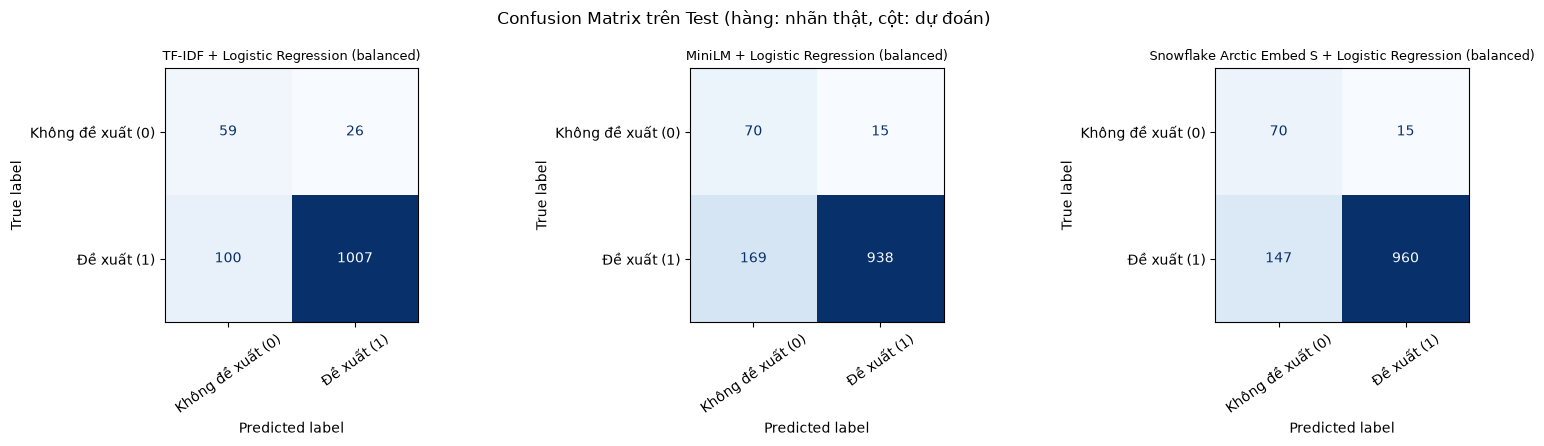

In [5]:
models = {
    'TF-IDF + Logistic Regression (balanced)': (tfidf_classifier, X_test_tfidf),
    'MiniLM + Logistic Regression (balanced)': (minilm_classifier, X_test_minilm),
    'Snowflake Arctic Embed S + Logistic Regression (balanced)': (arctic_classifier, X_test_arctic),
}
results = []
confusion_matrices = {}
for name, (classifier, test_features) in models.items():
    # Chỉ predict/đánh giá Test một lần cho mỗi pipeline.
    predictions = classifier.predict(test_features)
    class_precision, class_recall, class_f1, _ = precision_recall_fscore_support(
        y_test, predictions, labels=[0, 1], zero_division=0
    )
    results.append({
        'Phương pháp': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, pos_label=1, zero_division=0),
        'Recall': recall_score(y_test, predictions, pos_label=1, zero_division=0),
        'F1-score': f1_score(y_test, predictions, pos_label=1, zero_division=0),
        'Macro-F1': f1_score(y_test, predictions, average='macro', zero_division=0),
        'F1 lớp 0': class_f1[0],
    })
    confusion_matrices[name] = confusion_matrix(y_test, predictions, labels=[0, 1])

final_results = pd.DataFrame(results).set_index('Phương pháp')
display(final_results.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=['Không đề xuất (0)', 'Đề xuất (1)']
    ).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(name, fontsize=9)
    ax.tick_params(axis='x', labelrotation=35)
fig.suptitle('Confusion Matrix trên Test (hàng: nhãn thật, cột: dự đoán)')
fig.tight_layout()
plt.show()

## 5. Lưu kết quả và nhận xét
Lưu đúng bảng metric cuối cùng vào `results/final_comparison.csv`. Các nhận xét dưới đây mô tả xu hướng chung: TF-IDF gọn, nhanh và dễ giải thích nhưng biểu diễn từ vựng trực tiếp; embedding Transformer nắm ngữ nghĩa tốt hơn nhưng tốn thời gian tính toán; lớp 0 ít dữ liệu nên vẫn khó phân loại. Kết luận thực nghiệm cần dựa trên bảng và confusion matrix Test ở trên.

In [6]:
RESULTS_DIR = DATA_DIR.parent.parent / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
result_path = RESULTS_DIR / 'final_comparison.csv'
final_results.to_csv(result_path, encoding='utf-8')
best_model = final_results['Macro-F1'].idxmax()
print(f'Đã lưu: {result_path.resolve()}')
best_score = final_results.loc[best_model, 'Macro-F1']
print(f'Macro-F1 Test cao nhất: {best_model} ({best_score:.4f})')
print('Đánh giá Test đã hoàn tất; không điều chỉnh mô hình theo kết quả này.')

Đã lưu: C:\Users\ADMIN\Documents\Elden-Ring-Sentiment-Analysis\results\final_comparison.csv
Macro-F1 Test cao nhất: TF-IDF + Logistic Regression (balanced) (0.7124)
Đánh giá Test đã hoàn tất; không điều chỉnh mô hình theo kết quả này.
